# Model Evaluation

This notebook evaluates the selected classification model for predicting semiconductor chip failure based on manufacturing parameters.

The evaluation includes:

- Classification Report
- Confusion Matrix
- ROC Curve
- ROC-AUC Score
- Precision-Recall Curve
- Business Interpretation

In [15]:
import joblib
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)

In [16]:
model = joblib.load("../models/best_model.pkl")

X_test = joblib.load("../artifacts/X_test.pkl")

y_test = joblib.load("../artifacts/y_test.pkl")

In [17]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:,1]

In [18]:
print("Accuracy :", accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test,y_pred))
print("Recall   :", recall_score(y_test,y_pred))
print("F1 Score :", f1_score(y_test,y_pred))

Accuracy : 0.8465
Precision: 0.6415094339622641
Recall   : 0.20178041543026706
F1 Score : 0.30699774266365687


In [19]:
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.86      0.98      0.91      1663
           1       0.64      0.20      0.31       337

    accuracy                           0.85      2000
   macro avg       0.75      0.59      0.61      2000
weighted avg       0.82      0.85      0.81      2000



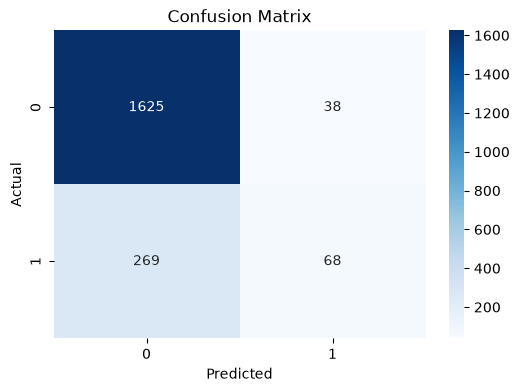

In [26]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    "../images/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
roc_auc = roc_auc_score(y_test,y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.7702321962917825


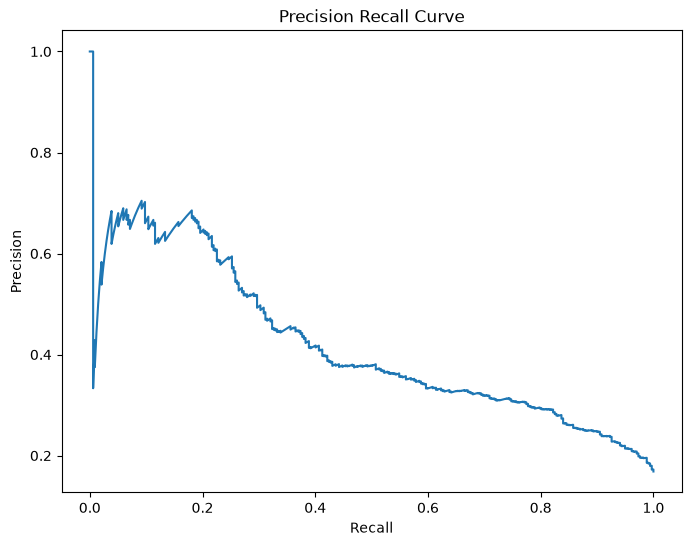

In [25]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision Recall Curve")

plt.savefig(
    "../images/precisionrecallcurve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
summary = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value":[
        accuracy_score(y_test,y_pred),
        precision_score(y_test,y_pred),
        recall_score(y_test,y_pred),
        f1_score(y_test,y_pred),
        roc_auc_score(y_test,y_prob)
    ]
})

summary

,Metric,Value
0,Accuracy,0.846500
1,Precision,0.641509
2,Recall,0.201780
3,F1 Score,0.306998
4,ROC AUC,0.770232


# Business Conclusion

Objective:
Predict whether a semiconductor chip will fail
based on manufacturing parameters.

Results:

- Accuracy ≈ 84%
- Recall ≈ 64%
- F1 Score ≈ 0.31

The chosen Logistic Regression model demonstrated the highest ability to identify failing semiconductor chips compared to the other evaluated algorithms.

For semiconductor manufacturing, failure detection is more critical than maximizing overall accuracy because undetected defective chips can reach production and increase operational risk.

Therefore, Logistic Regression was selected as the final deployment model.
